# 02 · The code atlas: every code, drawn from its geometry

**What this notebook is for.** Recognising a code by looking at it. Every code here is built from a picture: qubits on a line, a grid,
a triangle, a pentagon or a torus. The check matrices are *read off* that picture. For each code we show the same four views:

| view | what it shows |
|---|---|
| **lattice** | stabilizers as coloured faces (local codes) or stars (long-range codes). Red = X, blue = Z, purple = mixed |
| **Tanner graph** | qubits (circles) joined to the checks (squares) that measure them |
| **stabilizer matrix** | one row per stabilizer, one column per qubit |
| **logicals** | one logical pair: X̄ (red) and Z̄ (blue) |

Every number on these cards (n, k, d) is **computed** by `qdec`, not copied from a paper. d is found by brute force wherever that's affordable.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))      # make the repo's qdec package importable
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(2026)                        # fixed seed: same pictures every run
from qdec.families import catalogue, repetition, shor, steane, five_qubit, surface_unrotated, surface_rotated, toric
from qdec.families import hypergraph_product, classical_repetition_H, hamming_H, bb, BB_TABLE
from qdec.views import code_card, draw_lattice

## 1. The catalogue at a glance
n, k and the check weights are computed. d is brute-forced for codes up to ~41 qubits; for the BB family we quote the paper's d and check that no logical we find is lighter.

In [2]:
codes = catalogue()
print(f"{'code':34s} {'[[n,k,d]]':>14s}  {'CSS':5s} {'checks':>6s} {'weights':>8s}  d (brute force)")
for c in codes:
    w = (c.Sx | c.Sz).sum(1)
    d_bf = c.distance(max_weight=6) if (c.n <= 41 and c.info['family'] != 'repetition') else '-'
    print(f"{c.name:34s} {c.params():>14s}  {str(c.is_css):5s} {c.m:6d} {f'{w.min()}-{w.max()}':>8s}  {d_bf}")

code                                    [[n,k,d]]  CSS   checks  weights  d (brute force)
repetition d=5                          [[5,1,1]]  True       4      2-2  -
Shor [[9,1,3]]                          [[9,1,3]]  True       8      2-6  3
Steane [[7,1,3]]                        [[7,1,3]]  True       6      4-4  3
five-qubit [[5,1,3]]                    [[5,1,3]]  False      4      4-4  3
surface (unrotated) d=3                [[13,1,3]]  True      12      3-4  3


surface (unrotated) d=5                [[41,1,5]]  True      40      3-4  5
surface (rotated) d=3                   [[9,1,3]]  True       8      2-4  3
surface (rotated) d=5                  [[25,1,5]]  True      24      2-4  5
toric 4x4                              [[32,2,4]]  True      32      4-4  4
HGP(rep3, rep3) = surface d=3          [[13,1,3]]  True      12      3-4  3
HGP(Hamming, Hamming)                 [[58,16,3]]  True      42      5-7  -
BB [[72,12,6]]                        [[72,12,6]]  True      72      6-6  -
BB [[90,8,10]]                        [[90,8,10]]  True      90      6-6  -
BB [[108,8,10]]                      [[108,8,10]]  True     108      6-6  -
gross [[144,12,12]]                 [[144,12,12]]  True     144      6-6  -
BB [[288,12,18]]                    [[288,12,18]]  True     288      6-6  -


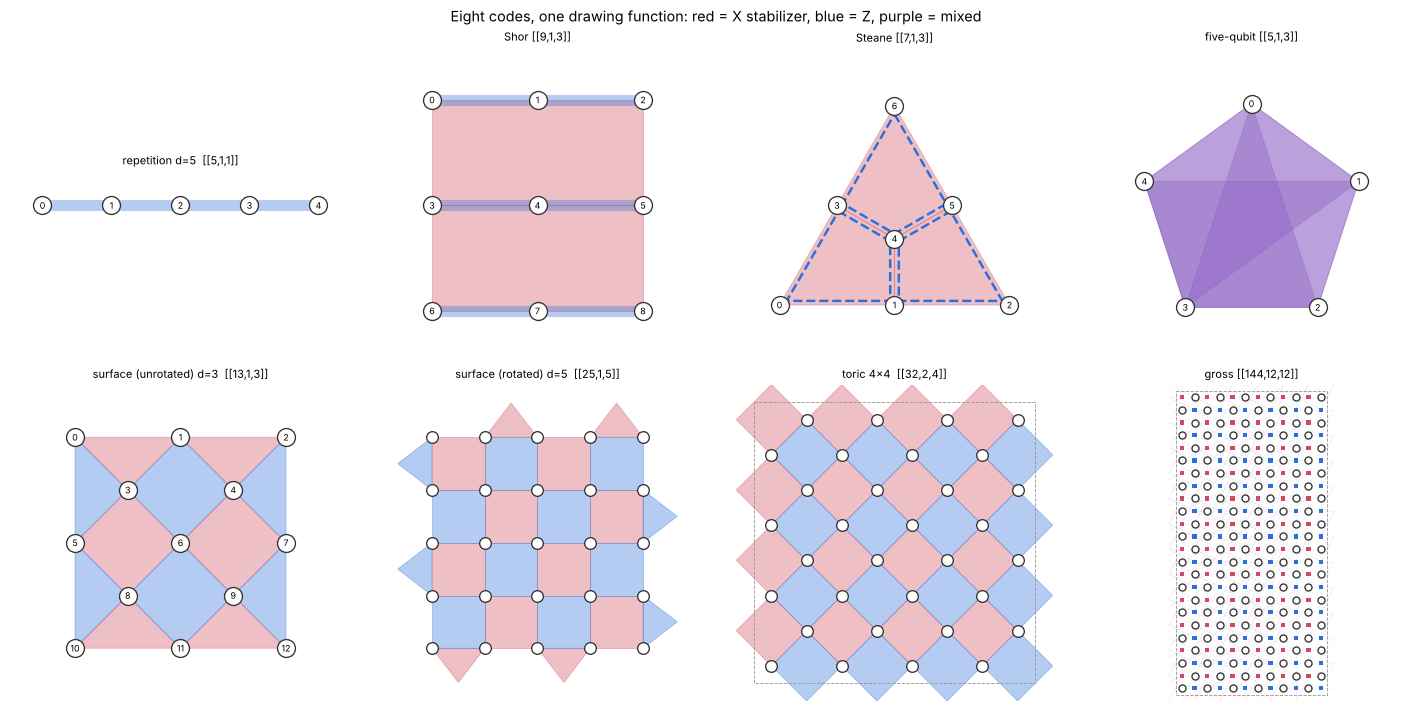

In [3]:
fig, axs = plt.subplots(2, 4, figsize=(18, 9))
for ax, c in zip(axs.flat, [repetition(5), shor(), steane(), five_qubit(), surface_unrotated(3), surface_rotated(5), toric(4), bb("gross")]):
    draw_lattice(c, ax, labels=c.n <= 13)
plt.suptitle("Eight codes, one drawing function: red = X stabilizer, blue = Z, purple = mixed", fontsize=13)
plt.tight_layout(); plt.show()

## 2. Repetition code: one dimension
The qubits sit in a row and each check compares two neighbours (Z_i Z_{i+1}). It catches bit flips only. One Z flip already changes the logical state,
so as a *quantum* code d = 1, while against X errors d = 5. This is where every decoder lesson starts.

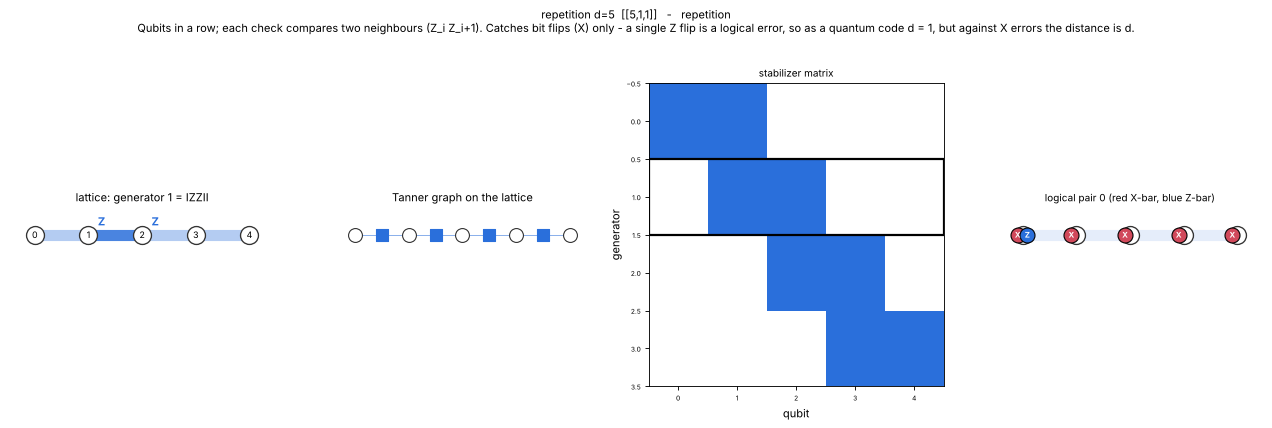

(d_X, d_Z) = (5, 1)


In [4]:
code_card(repetition(5)); plt.show()
print('(d_X, d_Z) =', repetition(5).css_distances())

## 3. Shor and Steane: the first real quantum codes
**Shor [[9,1,3]]**: a 3 × 3 grid. Pairwise Z checks along each row catch bit flips, and six-qubit X checks across two rows catch phase flips.
**Steane [[7,1,3]]**: a triangle with three faces, each face measured as XXXX **and** as ZZZZ. The faces are the parity checks of the Hamming [7,4,3] code,
so this is the smallest **colour code**.

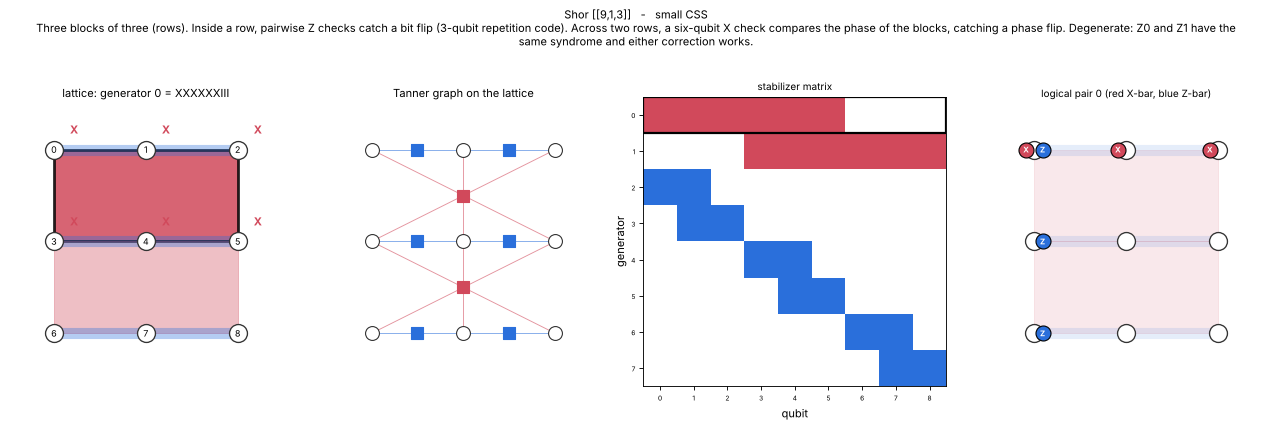

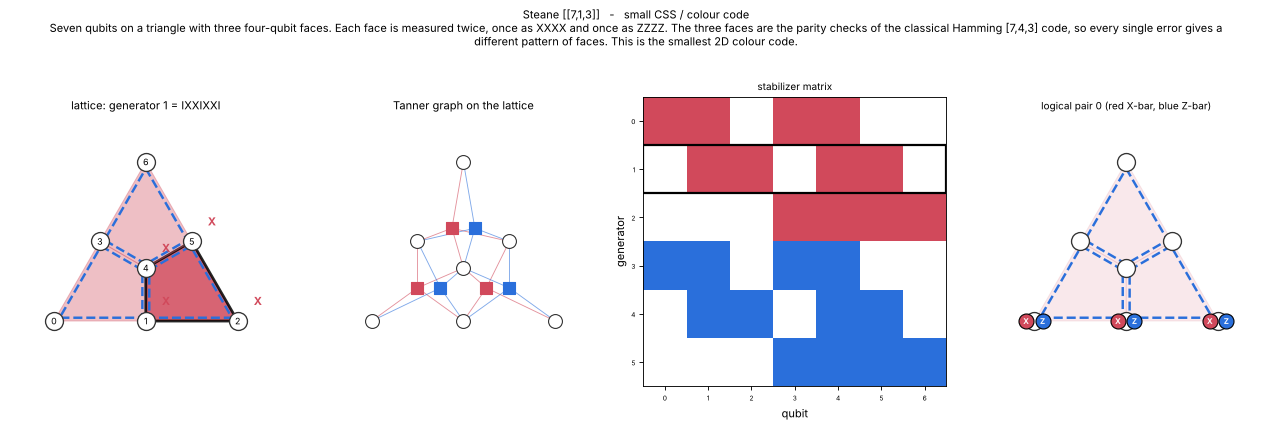

In [5]:
code_card(shor()); plt.show()
code_card(steane()); plt.show()

In [6]:
# Steane: every qubit is in a different set of faces -> every single error has its own syndrome
st = steane()
for q in range(7):
    faces = [f for f in range(3) if st.HX[f, q]]
    print(f"qubit {q}: in faces {faces}")

qubit 0: in faces [0]
qubit 1: in faces [0, 1]
qubit 2: in faces [1]
qubit 3: in faces [0, 2]
qubit 4: in faces [0, 1, 2]
qubit 5: in faces [1, 2]
qubit 6: in faces [2]


## 4. The five-qubit code: perfect, and not CSS
Five qubits on a ring, with one stabilizer `XZZXI` shifted around the ring. Each check mixes X and Z (purple). The 15 single-qubit errors
plus "no error" use up all 2⁴ = 16 syndromes exactly. That's what *perfect* means.

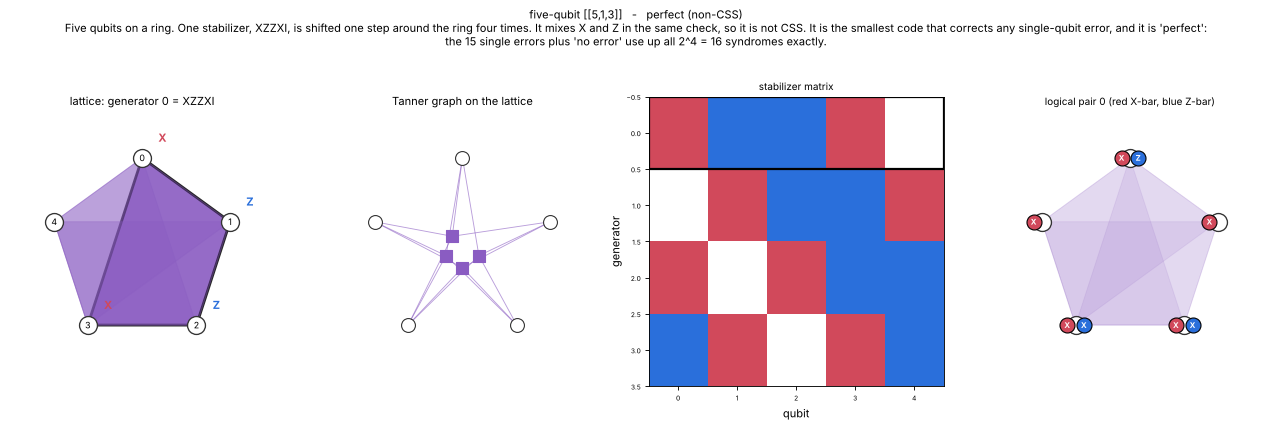

15 distinct syndromes for 15 single errors: {'X0': '0001', 'Z0': '1010', 'Y0': '1011', 'X1': '1000', 'Z1': '0101', 'Y1': '1101', 'X2': '1100', 'Z2': '0010', 'Y2': '1110', 'X3': '0110', 'Z3': '1001', 'Y3': '1111', 'X4': '0011', 'Z4': '0100', 'Y4': '0111'}


In [7]:
c5 = five_qubit()
code_card(c5, highlight=0); plt.show()
synd = {}
for q in range(5):
    for L, (ex, ez) in {"X": (1, 0), "Z": (0, 1), "Y": (1, 1)}.items():
        x = np.zeros(5, int); z = np.zeros(5, int); x[q] = ex; z[q] = ez
        synd[f"{L}{q}"] = "".join(map(str, c5.syndrome(x, z)))
print(len(set(synd.values())), "distinct syndromes for 15 single errors:", synd)

## 5. Surface codes: unrotated, rotated, toric
* **Unrotated**: qubits on the edges of a square grid. X checks on vertices, Z checks on faces. Boundary checks have 3 qubits.
* **Rotated**: d × d qubits with chessboard plaquettes and weight-2 half-moons on the boundary. About half the qubits for the same d.
* **Toric**: no boundary at all (a torus) and two logical qubits.
A logical operator is a string crossing the patch (or wrapping around the torus).

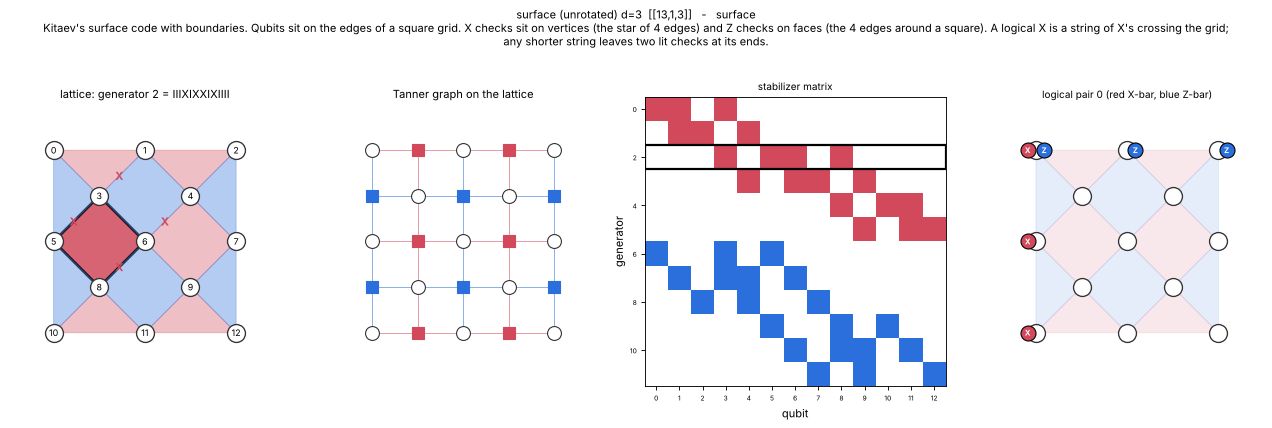

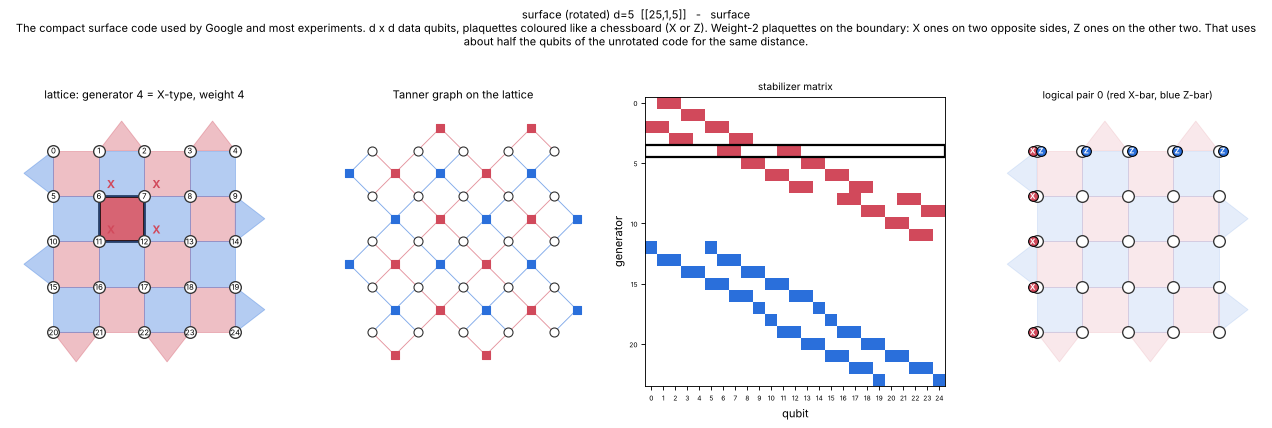

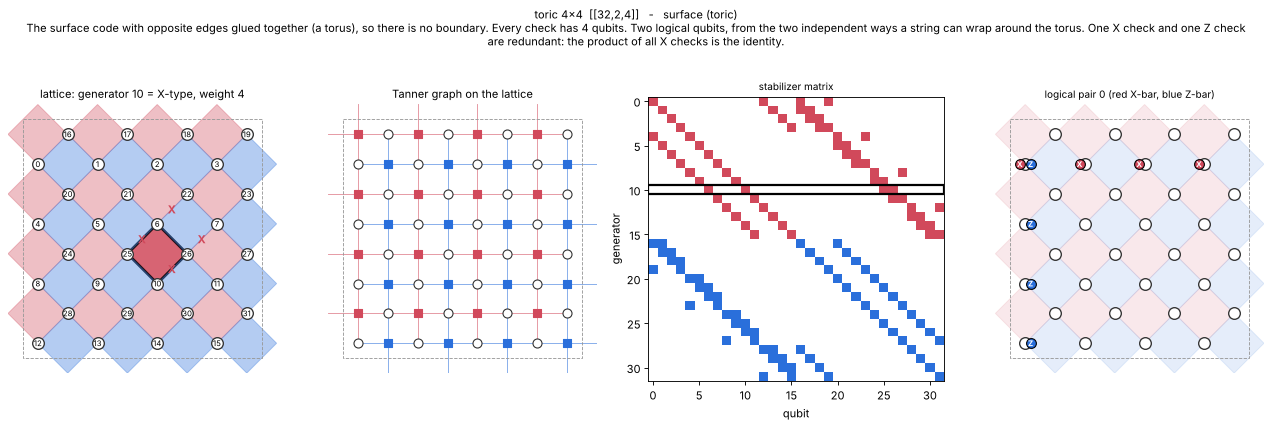

In [8]:
for c in [surface_unrotated(3), surface_rotated(5), toric(4)]:
    code_card(c); plt.show()

In [9]:
# distance grows with the patch: brute force confirms d for each size
for d in (3, 5):
    print(f"rotated d={d}: n={surface_rotated(d).n}, brute-force d={surface_rotated(d).distance(max_weight=d+1)};",
          f"unrotated d={d}: n={surface_unrotated(d).n}, brute-force d={surface_unrotated(d).distance(max_weight=d+1)}")

rotated d=3: n=9, brute-force d=3; unrotated d=3: n=13, brute-force d=3


rotated d=5: n=25, brute-force d=5; unrotated d=5: n=41, brute-force d=5


## 6. LDPC codes I: hypergraph products
Take two classical codes and multiply them (Tillich–Zémor). The **product of two repetition codes is the surface code**, with exactly the same n, k, d.
Use a better classical code (Hamming) and you get **16 logical qubits in 58**, but the checks are no longer local.

HGP(rep3, rep3): 13 1 3    surface (unrotated) d=3: 13 1


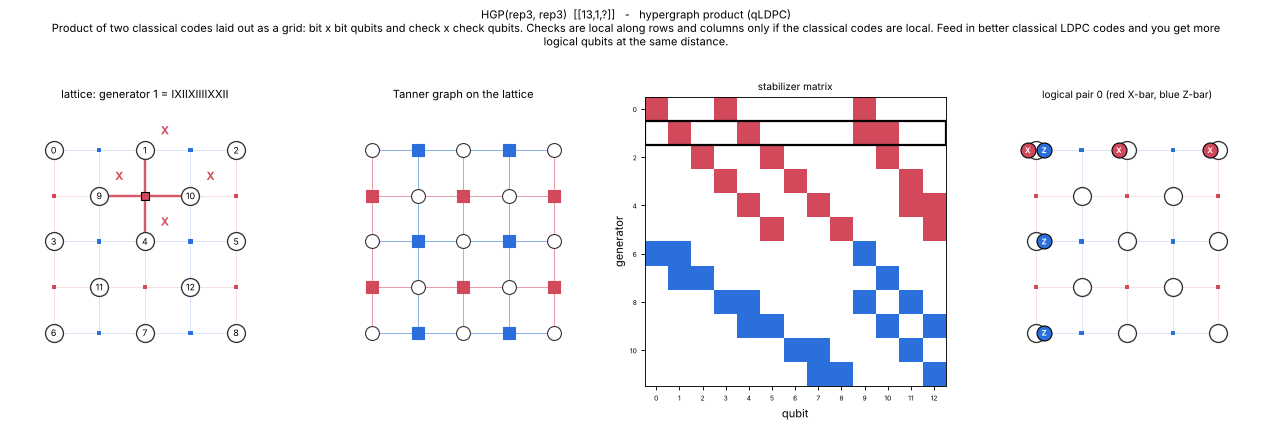

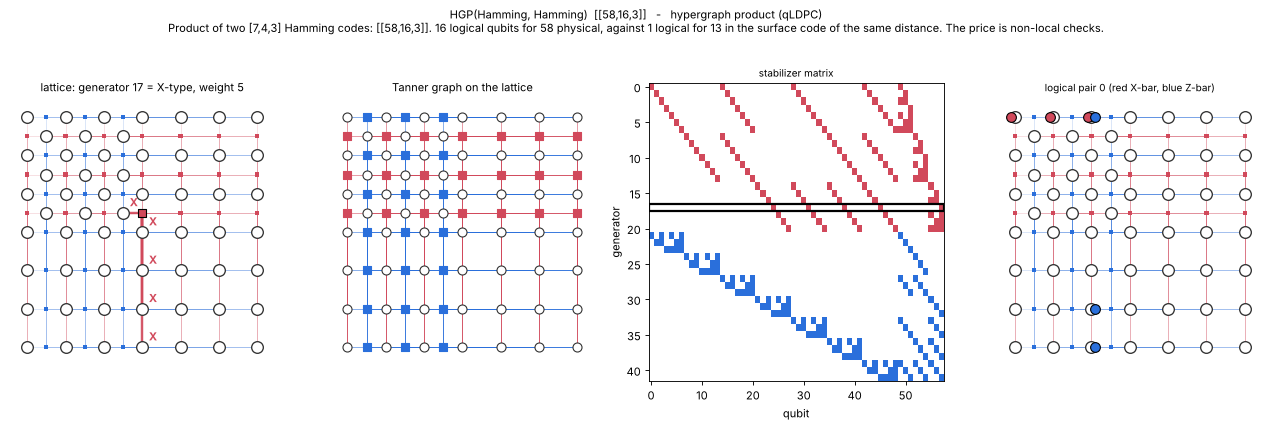

In [10]:
hp = hypergraph_product(classical_repetition_H(3), classical_repetition_H(3), "HGP(rep3, rep3)")
print("HGP(rep3, rep3):", hp.n, hp.k, hp.distance(6), "   surface (unrotated) d=3:", surface_unrotated(3).n, surface_unrotated(3).k)
hh = [c for c in codes if c.name.startswith("HGP(Hamming")][0]
code_card(hp); plt.show()
code_card(hh); plt.show()

## 7. LDPC codes II: the bivariate-bicycle family (gross code)
Two polynomials A, B in x and y on an l × m torus. Each term is an "arrow" from a check to a qubit, the same arrow in every cell.
Bravyi et al.'s table has five members, and the gross code [[144,12,12]] is one of them. In the toric layout each check has 4 neighbour edges and 2 long-range ones.

In [11]:
for name, (l, m, A, B, d) in BB_TABLE.items():
    c = bb(name)
    print(f"{c.name:22s} l={l:2d} m={m:2d}  A={c.info['A']:16s} B={c.info['B']:14s}  n={c.n:3d} k={c.k:2d} (computed)  d={d} (paper)  n/k = {c.n/c.k:.0f}")

BB [[72,12,6]]         l= 6 m= 6  A=x^3 + y + y^2    B=y^3 + x + x^2   n= 72 k=12 (computed)  d=6 (paper)  n/k = 6
BB [[90,8,10]]         l=15 m= 3  A=x^9 + y + y^2    B=1 + x^2 + x^7   n= 90 k= 8 (computed)  d=10 (paper)  n/k = 11
BB [[108,8,10]]        l= 9 m= 6  A=x^3 + y + y^2    B=y^3 + x + x^2   n=108 k= 8 (computed)  d=10 (paper)  n/k = 14
gross [[144,12,12]]    l=12 m= 6  A=x^3 + y + y^2    B=y^3 + x + x^2   n=144 k=12 (computed)  d=12 (paper)  n/k = 12
BB [[288,12,18]]       l=12 m=12  A=x^3 + y^2 + y^7  B=y^3 + x + x^2   n=288 k=12 (computed)  d=18 (paper)  n/k = 24


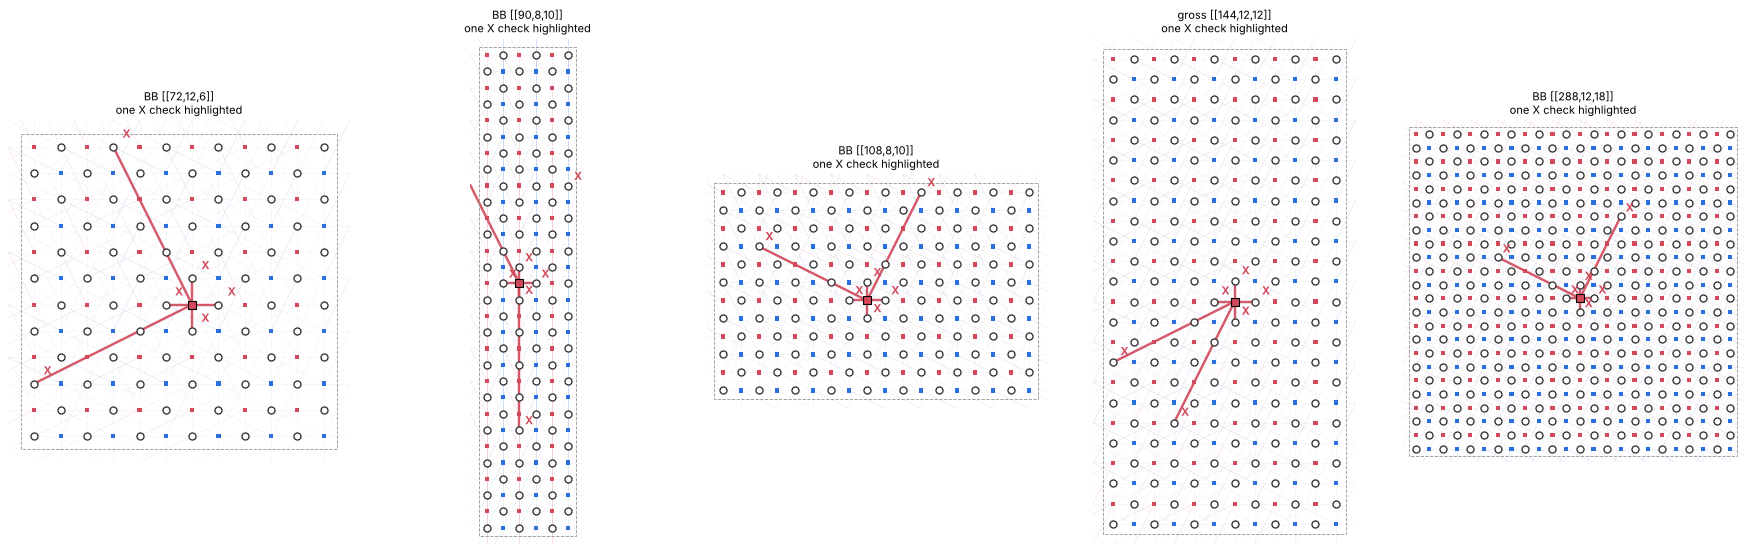

In [12]:
fig, axs = plt.subplots(1, 5, figsize=(22, 7))
for ax, name in zip(axs, BB_TABLE):
    c = bb(name)
    centre = c.geometry.qubit_pos.mean(0)
    hl = int(np.argmin(np.linalg.norm(c.geometry.check_pos - centre, axis=1)))
    draw_lattice(c, ax, highlight=hl, labels=False, title=f"{c.name}\none X check highlighted")
plt.tight_layout(); plt.show()

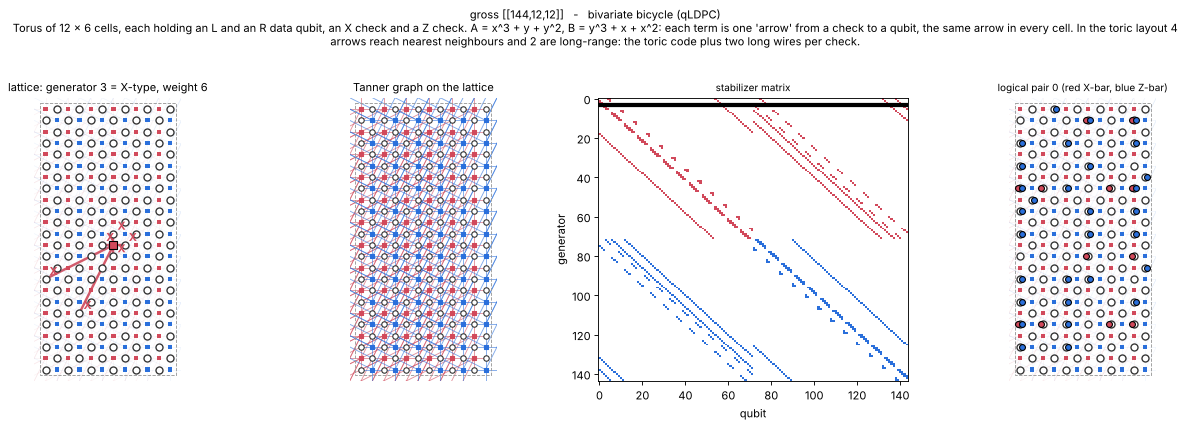

In [13]:
code_card(bb('gross')); plt.show()

## 8. Reading the pictures: what tells the families apart
| you see… | it is… |
|---|---|
| a line of qubits, checks between neighbours | **repetition** |
| faces where X and Z checks are separate colours | **CSS**: surface, toric, Shor, HGP, BB |
| the same face carrying both X and Z | **colour code** (Steane) |
| purple checks mixing X and Z | **non-CSS** (five-qubit) |
| square plaquettes with half-moons on the edges | **rotated surface** |
| no edges, everything wraps | **toric** (and BB codes) |
| stars with long spokes | **qLDPC**: checks reach far away (HGP, BB, gross) |

Next: `03_widgets_explorer.ipynb` lets you click around. `04_circuits_and_detector_graphs.ipynb` turns these codes into noisy circuits.